# U-Net Lesion Segmentation: Real GLS Diseased Leaves (Linux / Cloud GPU)

Trains a basic U-Net to segment lesion masks from diseased GLS leaf images.

**Input:** RGB diseased image  
**Target:** Binary lesion mask

**Data:** `data/diseased/gls` with masks from `data/masks/lesion_real/gls`

**Target hardware:** Lambda Labs A100 (mixed precision enabled)

In [1]:
# 1. Imports
import os
import sys
import json
import time
import random
from pathlib import Path

import numpy as np
from PIL import Image
!{sys.executable} -m pip install tqdm
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 KB 2.9 MB/s eta 0:00:00


In [2]:
# 2. Resolve repo root + import UNet architecture
repo_root = Path.cwd().resolve()
if repo_root.name == 'image_seg':
    repo_root = repo_root.parents[1]
elif repo_root.name == 'src':
    repo_root = repo_root.parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.models.unet import UNet

print(f'Repo root: {repo_root}')
print('UNet loaded from src/models/unet.py')

Repo root: /lambda/nfs/test-2
UNet loaded from src/models/unet.py


In [13]:
# =============================================================
# 3. CONFIGURATION — tuned for Lambda A100
# =============================================================

# ----- Source data paths (original data; used only for split generation) -----
SOURCE_IMAGE_DIR = os.path.join(str(repo_root), 'data', 'degls_dataset', 'train', 'image')
SOURCE_MASK_DIR  = os.path.join(str(repo_root), 'data', 'degls_dataset', 'train', 'mask')

# ----- Processed split dataset root -----
SPLIT_ROOT = os.path.join(str(repo_root), 'data', 'unet_image_seg_degls_images')
TRAIN_IMAGE_DIR = os.path.join(SPLIT_ROOT, 'train', 'image')
TRAIN_MASK_DIR  = os.path.join(SPLIT_ROOT, 'train', 'mask')
TEST_IMAGE_DIR  = os.path.join(SPLIT_ROOT, 'test', 'image')
TEST_MASK_DIR   = os.path.join(SPLIT_ROOT, 'test', 'mask')

os.makedirs(SPLIT_ROOT, exist_ok=True)
os.makedirs(TRAIN_IMAGE_DIR, exist_ok=True)
os.makedirs(TRAIN_MASK_DIR, exist_ok=True)
os.makedirs(TEST_IMAGE_DIR, exist_ok=True)
os.makedirs(TEST_MASK_DIR, exist_ok=True)

# ----- Output directories -----
CHECKPOINT_DIR = os.path.join(str(repo_root), 'src', 'models', 'checkpoints')
LOG_DIR        = os.path.join(str(repo_root), 'results', 'logs')
SAMPLE_DIR     = os.path.join(str(repo_root), 'results', 'figures', 'training_samples')
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)
os.makedirs(SAMPLE_DIR, exist_ok=True)

# ----- Split + augmentation generation -----
TEST_SPLIT            = 0.10
REBUILD_SPLIT_DATASET = True
TRAIN_AUG_PER_IMAGE   = 1
TEST_AUG_PER_IMAGE    = 0

# ----- Training -----
SEED         = 42
NUM_EPOCHS   = 100
BATCH_SIZE   = 24
NUM_WORKERS  = 8
IMAGE_SIZE   = 512
SAVE_EVERY   = 50
SAMPLE_EVERY = 5

# ----- Optimizer / model -----
LEARNING_RATE = 1e-4
WEIGHT_DECAY  = 1e-5
BASE_CHANNELS = 64
POS_WEIGHT    = 3.0

# ----- Runtime -----
USE_AMP = True

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True

print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU name: {torch.cuda.get_device_name(0)}')
print(f'Image size: {IMAGE_SIZE}x{IMAGE_SIZE} | Batch size: {BATCH_SIZE}')
print(f'Source image dir: {SOURCE_IMAGE_DIR}')
print(f'Source mask dir:  {SOURCE_MASK_DIR}')
print(f'Split root:       {SPLIT_ROOT}')

Device: cuda
GPU name: NVIDIA A100-SXM4-40GB
Image size: 512x512 | Batch size: 24
Source image dir: /lambda/nfs/test-2/data/degls_dataset/train/image
Source mask dir:  /lambda/nfs/test-2/data/degls_dataset/train/mask
Split root:       /lambda/nfs/test-2/data/unet_image_seg_degls_images


In [15]:
# 4. Build train/test folders, split, augment, then create dataloaders from split folders
import shutil

IMG_EXTS = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}

def list_image_files(folder):
    return sorted([p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXTS])

def build_pairs(image_dir, mask_dir):
    image_files = list_image_files(image_dir)
    mask_files = list_image_files(mask_dir)
    mask_map = {p.stem: p for p in mask_files}

    pairs = []
    missing_masks = []

    for img_p in image_files:
        stem = img_p.stem
        candidates = [stem, f'{stem}_mask', f'mask_{stem}', stem.replace('_image', ''), stem.replace('image_', ''), stem.replace('image_', 'mask_')]
        match = None
        for c in candidates:
            if c in mask_map:
                match = mask_map[c]
                break
        if match is None:
            missing_masks.append(img_p.name)
            continue
        pairs.append((img_p, match))

    if len(pairs) == 0:
        raise RuntimeError(f'No valid image/mask pairs found. Check: {image_dir} and {mask_dir}')

    if missing_masks:
        print(f'Warning: {len(missing_masks)} images had no matching mask and were skipped.')

    return pairs

def ensure_clean_split_dirs():
    if REBUILD_SPLIT_DATASET and os.path.exists(SPLIT_ROOT):
        shutil.rmtree(SPLIT_ROOT)

    for d in [TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TEST_IMAGE_DIR, TEST_MASK_DIR]:
        os.makedirs(d, exist_ok=True)

def apply_aug(img, mask, aug_idx):
    # Deterministic-ish augment variants by index.
    if aug_idx % 4 == 0:
        img = img.transpose(Image.FLIP_LEFT_RIGHT)
        mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
    elif aug_idx % 4 == 1:
        img = img.transpose(Image.FLIP_TOP_BOTTOM)
        mask = mask.transpose(Image.FLIP_TOP_BOTTOM)
    elif aug_idx % 4 == 2:
        img = img.rotate(90, resample=Image.BILINEAR)
        mask = mask.rotate(90, resample=Image.NEAREST)
    else:
        img = img.rotate(270, resample=Image.BILINEAR)
        mask = mask.rotate(270, resample=Image.NEAREST)
    return img, mask

def save_split_with_augmentation(train_pairs, test_pairs):
    def save_one_split(pairs, out_img_dir, out_mask_dir, split_name, n_aug):
        for idx, (img_path, mask_path) in enumerate(pairs):
            stem = f'{split_name}_{idx:05d}'

            img = Image.open(img_path).convert('RGB')
            mask = Image.open(mask_path).convert('L')

            img.save(os.path.join(out_img_dir, f'{stem}.png'))
            mask.save(os.path.join(out_mask_dir, f'{stem}.png'))

            for a in range(n_aug):
                aug_img, aug_mask = apply_aug(img, mask, a)
                aug_stem = f'{stem}_aug{a+1:02d}'
                aug_img.save(os.path.join(out_img_dir, f'{aug_stem}.png'))
                aug_mask.save(os.path.join(out_mask_dir, f'{aug_stem}.png'))

    save_one_split(train_pairs, TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, 'train', TRAIN_AUG_PER_IMAGE)
    save_one_split(test_pairs, TEST_IMAGE_DIR, TEST_MASK_DIR, 'test', TEST_AUG_PER_IMAGE)

def build_train_test_folders_from_source():
    all_pairs = build_pairs(SOURCE_IMAGE_DIR, SOURCE_MASK_DIR)
    random.shuffle(all_pairs)

    n_test = max(1, int(len(all_pairs) * TEST_SPLIT))
    test_pairs = all_pairs[:n_test]
    train_pairs = all_pairs[n_test:]

    ensure_clean_split_dirs()
    save_split_with_augmentation(train_pairs, test_pairs)

    print(f'Original total pairs: {len(all_pairs)}')
    print(f'Original split -> train: {len(train_pairs)} | test: {len(test_pairs)}')

if REBUILD_SPLIT_DATASET:
    build_train_test_folders_from_source()

class GLSLesionDataset(Dataset):
    def __init__(self, image_dir, mask_dir, image_size=512):
        self.image_files = list_image_files(image_dir)
        self.mask_files = list_image_files(mask_dir)

        if len(self.image_files) != len(self.mask_files):
            raise RuntimeError('Image/mask file count mismatch in split folders.')

        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_size = image_size

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = self.image_files[idx]
        mask_path = self.mask_files[idx]

        img = Image.open(img_path).convert('RGB')
        mask = Image.open(mask_path).convert('L')

        img = img.resize((self.image_size, self.image_size), Image.BILINEAR)
        mask = mask.resize((self.image_size, self.image_size), Image.NEAREST)

        img_np = np.asarray(img, dtype=np.float32) / 255.0
        mask_np = np.asarray(mask, dtype=np.float32) / 255.0
        mask_np = (mask_np > 0.5).astype(np.float32)

        img_t = torch.from_numpy(img_np).permute(2, 0, 1).contiguous()
        mask_t = torch.from_numpy(mask_np).unsqueeze(0).contiguous()

        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        img_t = (img_t - mean) / std

        return img_t, mask_t, img_path.name

train_dataset = GLSLesionDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, image_size=IMAGE_SIZE)
test_dataset = GLSLesionDataset(TEST_IMAGE_DIR, TEST_MASK_DIR, image_size=IMAGE_SIZE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f'Augmented train files: {len(train_dataset)}')
print(f'Augmented test files:  {len(test_dataset)}')

Original total pairs: 639
Original split -> train: 576 | test: 63
Augmented train files: 1152
Augmented test files:  63


In [16]:
# 5. Losses, metrics, model, optimizer
def dice_loss_from_logits(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    num = 2.0 * (probs * targets).sum(dim=(1, 2, 3)) + eps
    den = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + eps
    dice = num / den
    return 1.0 - dice.mean()

def combined_loss(logits, targets, bce_weight=0.5, dice_weight=0.5):
    pos_weight = torch.tensor([POS_WEIGHT], device=logits.device)
    bce = F.binary_cross_entropy_with_logits(logits, targets, pos_weight=pos_weight)
    dsc = dice_loss_from_logits(logits, targets)
    return bce_weight * bce + dice_weight * dsc, bce.detach(), dsc.detach()

@torch.no_grad()
def dice_score(logits, targets, threshold=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    pred = (probs > threshold).float()
    num = 2.0 * (pred * targets).sum(dim=(1, 2, 3)) + eps
    den = pred.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) + eps
    return (num / den).mean().item()

@torch.no_grad()
def iou_score(logits, targets, threshold=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    pred = (probs > threshold).float()
    inter = (pred * targets).sum(dim=(1, 2, 3))
    union = pred.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) - inter
    return ((inter + eps) / (union + eps)).mean().item()

net = UNet(in_channels=3, out_channels=1, base_channels=BASE_CHANNELS).to(device)
optimizer = optim.AdamW(net.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scaler = GradScaler(device.type, enabled=(USE_AMP and device.type == 'cuda'))

param_count = sum(p.numel() for p in net.parameters() if p.requires_grad)
print(f'Trainable params: {param_count:,}')

history = {
    'train_loss': [],
    'train_bce': [],
    'train_dice_loss': [],
    'test_loss': [],
    'test_dice': [],
    'test_iou': [],
    'epoch_time': []
}

best_test_dice = -1.0
best_ckpt_path = os.path.join(CHECKPOINT_DIR, 'unet_gls_lesion_best.pth')

Trainable params: 31,037,633


In [17]:
# 6. Training + test loop
def evaluate_test(net, loader):
    net.eval()
    run_loss = 0.0
    run_dice = 0.0
    run_iou = 0.0

    with torch.no_grad():
        for images, masks, _ in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            with autocast(device_type=device.type, enabled=(USE_AMP and device.type == 'cuda')):
                logits = net(images)
                loss, _, _ = combined_loss(logits, masks)

            bs = images.size(0)
            run_loss += loss.item() * bs
            run_dice += dice_score(logits, masks) * bs
            run_iou += iou_score(logits, masks) * bs

    n = len(loader.dataset)
    return run_loss / n, run_dice / n, run_iou / n

print(f'Training for {NUM_EPOCHS} epochs...')
print('=' * 70)

for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()
    net.train()

    run_loss = 0.0
    run_bce = 0.0
    run_dice_loss = 0.0

    progress = tqdm(train_loader, desc=f'Epoch {epoch}/{NUM_EPOCHS}')
    for images, masks, _ in progress:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast(device_type=device.type, enabled=(USE_AMP and device.type == 'cuda')):
            logits = net(images)
            loss, bce_term, dice_term = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        bs = images.size(0)
        run_loss += loss.item() * bs
        run_bce += bce_term.item() * bs
        run_dice_loss += dice_term.item() * bs

        progress.set_postfix({
            'loss': f'{loss.item():.4f}',
            'bce': f'{bce_term.item():.4f}',
            'diceL': f'{dice_term.item():.4f}'
        })

    n_train = len(train_loader.dataset)
    train_loss = run_loss / n_train
    train_bce = run_bce / n_train
    train_dice_loss = run_dice_loss / n_train

    test_loss, test_dice, test_iou = evaluate_test(net, test_loader)
    elapsed = time.time() - start_time

    history['train_loss'].append(train_loss)
    history['train_bce'].append(train_bce)
    history['train_dice_loss'].append(train_dice_loss)
    history['test_loss'].append(test_loss)
    history['test_dice'].append(test_dice)
    history['test_iou'].append(test_iou)
    history['epoch_time'].append(elapsed)

    print(
        f'Epoch {epoch:03d}/{NUM_EPOCHS} [{elapsed:.1f}s] | '
        f'train_loss: {train_loss:.4f}  test_loss: {test_loss:.4f}  '
        f'test_dice: {test_dice:.4f}  test_iou: {test_iou:.4f}'
    )

    if test_dice > best_test_dice:
        best_test_dice = test_dice
        torch.save({
            'epoch': epoch,
            'model_state_dict': net.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_test_dice': best_test_dice,
            'history': history,
            'config': {
                'SOURCE_IMAGE_DIR': SOURCE_IMAGE_DIR,
                'SOURCE_MASK_DIR': SOURCE_MASK_DIR,
                'SPLIT_ROOT': SPLIT_ROOT,
                'TEST_SPLIT': TEST_SPLIT,
                'TRAIN_AUG_PER_IMAGE': TRAIN_AUG_PER_IMAGE,
                'TEST_AUG_PER_IMAGE': TEST_AUG_PER_IMAGE,
                'IMAGE_SIZE': IMAGE_SIZE,
                'BATCH_SIZE': BATCH_SIZE,
                'NUM_EPOCHS': NUM_EPOCHS,
                'LEARNING_RATE': LEARNING_RATE,
                'WEIGHT_DECAY': WEIGHT_DECAY,
                'BASE_CHANNELS': BASE_CHANNELS,
                'POS_WEIGHT': POS_WEIGHT
            }
        }, best_ckpt_path)
        print(f'  >> New best checkpoint saved: {best_ckpt_path}')

    if epoch % SAVE_EVERY == 0:
        periodic_path = os.path.join(CHECKPOINT_DIR, f'unet_gls_lesion_epoch{epoch:03d}.pth')
        torch.save({
            'epoch': epoch,
            'model_state_dict': net.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_test_dice': best_test_dice,
            'history': history
        }, periodic_path)
        print(f'  >> Periodic checkpoint saved: {periodic_path}')

history_path = os.path.join(LOG_DIR, 'unet_gls_lesion_history.json')
with open(history_path, 'w') as f:
    json.dump(history, f, indent=2)

print('=' * 70)
print(f'Training complete. Best test Dice: {best_test_dice:.4f}')
print(f'Best checkpoint: {best_ckpt_path}')
print(f'History JSON: {history_path}')

Training for 100 epochs...


Epoch 1/100: 100%|██████████| 48/48 [00:19<00:00,  2.51it/s, loss=0.5001, bce=0.3446, diceL=0.6556]


Epoch 001/100 [21.3s] | train_loss: 0.5787  test_loss: 0.5244  test_dice: 0.6953  test_iou: 0.5686
  >> New best checkpoint saved: /lambda/nfs/test-2/src/models/checkpoints/unet_gls_lesion_best.pth


Epoch 2/100: 100%|██████████| 48/48 [00:19<00:00,  2.53it/s, loss=0.4185, bce=0.2925, diceL=0.5446]


Epoch 002/100 [20.3s] | train_loss: 0.4844  test_loss: 0.4834  test_dice: 0.7080  test_iou: 0.5807
  >> New best checkpoint saved: /lambda/nfs/test-2/src/models/checkpoints/unet_gls_lesion_best.pth


...

Epoch 098/100 [20.4s] | train_loss: 0.1219  test_loss: 0.1278  test_dice: 0.8541  test_iou: 0.7679


Epoch 99/100: 100%|██████████| 48/48 [00:19<00:00,  2.53it/s, loss=0.1086, bce=0.0724, diceL=0.1448]


Epoch 099/100 [20.3s] | train_loss: 0.1198  test_loss: 0.1214  test_dice: 0.8901  test_iou: 0.8056
  >> New best checkpoint saved: /lambda/nfs/test-2/src/models/checkpoints/unet_gls_lesion_best.pth


Epoch 100/100: 100%|██████████| 48/48 [00:19<00:00,  2.51it/s, loss=0.1141, bce=0.0634, diceL=0.1649]


Epoch 100/100 [20.5s] | train_loss: 0.1212  test_loss: 0.1241  test_dice: 0.8347  test_iou: 0.7455
  >> Periodic checkpoint saved: /lambda/nfs/test-2/src/models/checkpoints/unet_gls_lesion_epoch100.pth
Training complete. Best test Dice: 0.8901
Best checkpoint: /lambda/nfs/test-2/src/models/checkpoints/unet_gls_lesion_best.pth
History JSON: /lambda/nfs/test-2/results/logs/unet_gls_lesion_history.json


In [18]:
# 7. Plot training curves
epochs = np.arange(1, len(history['train_loss']) + 1)

fig, axs = plt.subplots(2, 2, figsize=(14, 10))

axs[0, 0].plot(epochs, history['train_loss'], label='train_loss', color='tab:blue')
axs[0, 0].plot(epochs, history['test_loss'], label='test_loss', color='tab:orange')
axs[0, 0].set_title('Total Loss')
axs[0, 0].set_xlabel('Epoch'); axs[0, 0].set_ylabel('Loss'); axs[0, 0].grid(True); axs[0, 0].legend()

axs[0, 1].plot(epochs, history['train_bce'], label='train_bce', color='tab:green')
axs[0, 1].plot(epochs, history['train_dice_loss'], label='train_dice_loss', color='tab:red')
axs[0, 1].set_title('Train Loss Components')
axs[0, 1].set_xlabel('Epoch'); axs[0, 1].set_ylabel('Loss'); axs[0, 1].grid(True); axs[0, 1].legend()

axs[1, 0].plot(epochs, history['test_dice'], label='test_dice', color='tab:purple')
axs[1, 0].set_title('Test Dice')
axs[1, 0].set_xlabel('Epoch'); axs[1, 0].set_ylabel('Dice'); axs[1, 0].grid(True); axs[1, 0].legend()

axs[1, 1].plot(epochs, history['test_iou'], label='test_iou', color='tab:brown')
axs[1, 1].set_title('Test IoU')
axs[1, 1].set_xlabel('Epoch'); axs[1, 1].set_ylabel('IoU'); axs[1, 1].grid(True); axs[1, 1].legend()

plt.suptitle('U-Net GLS Lesion Segmentation Training Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
curve_path = os.path.join(LOG_DIR, 'unet_gls_lesion_curves.png')
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Curves saved to: {curve_path}')

Curves saved to: /lambda/nfs/test-2/results/logs/unet_gls_lesion_curves.png


In [19]:
# 8. Quick qualitative check on test samples
net.eval()
num_show = min(6, len(test_dataset))
fig, axs = plt.subplots(num_show, 4, figsize=(16, 4 * num_show))
if num_show == 1:
    axs = np.expand_dims(axs, axis=0)

def denorm(img_t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1).to(img_t.device)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1).to(img_t.device)
    return (img_t * std + mean).clamp(0, 1)

with torch.no_grad():
    for i in range(num_show):
        img_t, mask_t, fname = test_dataset[i]
        logits = net(img_t.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits).squeeze().cpu().numpy() > 0.5).astype(np.float32)

        img_np = denorm(img_t).permute(1, 2, 0).cpu().numpy()
        gt_np = mask_t.squeeze(0).cpu().numpy()

        # Overlay prediction in red on image
        overlay = img_np.copy()
        overlay[pred > 0.5] = [1, 0, 0]
        blended = img_np * 0.6 + overlay * 0.4

        axs[i, 0].imshow(img_np)
        axs[i, 0].set_title(f'Input: {fname}')
        axs[i, 0].axis('off')
        axs[i, 1].imshow(gt_np, cmap='gray')
        axs[i, 1].set_title('Ground Truth Mask')
        axs[i, 1].axis('off')
        axs[i, 2].imshow(pred, cmap='gray')
        axs[i, 2].set_title('Predicted Mask')
        axs[i, 2].axis('off')
        axs[i, 3].imshow(blended)
        axs[i, 3].set_title('Prediction Overlay')
        axs[i, 3].axis('off')

plt.tight_layout()
qual_path = os.path.join(SAMPLE_DIR, 'unet_gls_test_predictions.png')
plt.savefig(qual_path, dpi=150, bbox_inches='tight')
print(f'Test prediction grid saved to: {qual_path}')
plt.show()

Test prediction grid saved to: /lambda/nfs/test-2/results/figures/training_samples/unet_gls_test_predictions.png


In [20]:
# 9. Compute final IoU and Dice (F1) score on test set
@torch.no_grad()
def compute_test_metrics(net, test_loader):
    net.eval()
    total_iou = 0.0
    total_dice = 0.0
    n = 0
    for images, masks, _ in tqdm(test_loader, desc='Test metrics'):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        logits = net(images)
        total_iou += iou_score(logits, masks) * images.size(0)
        total_dice += dice_score(logits, masks) * images.size(0)
        n += images.size(0)
    avg_iou = total_iou / n
    avg_dice = total_dice / n
    return avg_iou, avg_dice

iou, dice = compute_test_metrics(net, test_loader)
print(f'Final Test IoU:  {iou:.4f}')
print(f'Final Test Dice (F1): {dice:.4f}')

Test metrics: 100%|██████████| 3/3 [00:09<00:00,  3.22s/it]

Final Test IoU:  0.7455
Final Test Dice (F1): 0.8347


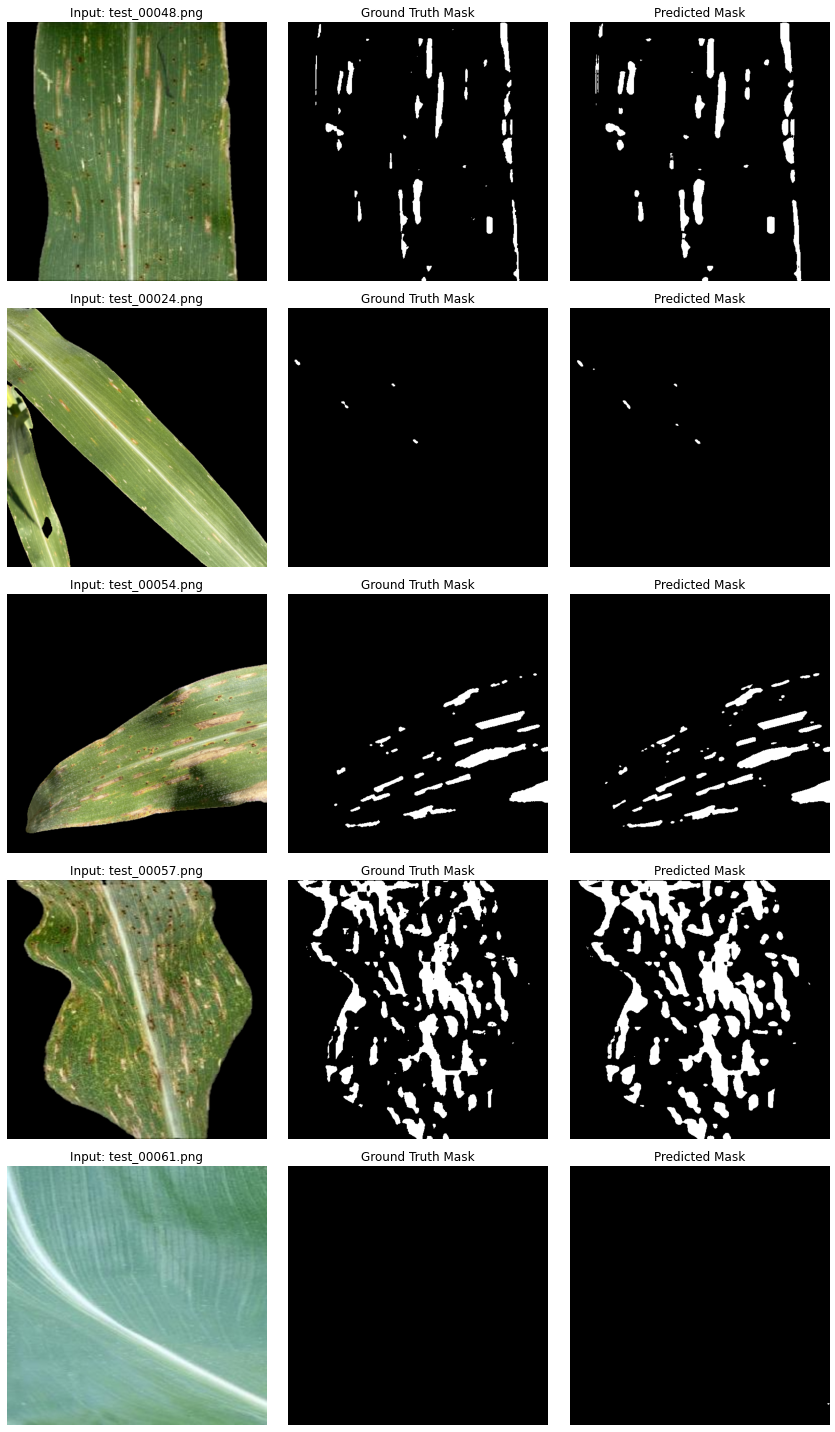

In [23]:
%matplotlib inline
# 10. Run model on 5 random test images and output predictions
import random
from PIL import Image
import matplotlib.pyplot as plt
@torch.no_grad()
def show_test_predictions(net, test_dataset, num_samples=5):
    net.eval()
    indices = random.sample(range(len(test_dataset)), min(num_samples, len(test_dataset)))
    fig, axs = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))
    if len(indices) == 1:
        axs = np.expand_dims(axs, axis=0)
    for i, idx in enumerate(indices):
        img_t, mask_t, fname = test_dataset[idx]
        logits = net(img_t.unsqueeze(0).to(device))
        pred = (torch.sigmoid(logits).squeeze().cpu().numpy() > 0.5).astype(np.float32)
        img_np = img_t.permute(1, 2, 0).cpu().numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
        img_np = np.clip(img_np, 0, 1)
        gt_np = mask_t.squeeze(0).cpu().numpy()
        axs[i, 0].imshow(img_np)
        axs[i, 0].set_title(f'Input: {fname}')
        axs[i, 0].axis('off')
        axs[i, 1].imshow(gt_np, cmap='gray')
        axs[i, 1].set_title('Ground Truth Mask')
        axs[i, 1].axis('off')
        axs[i, 2].imshow(pred, cmap='gray')
        axs[i, 2].set_title('Predicted Mask')
        axs[i, 2].axis('off')
    plt.tight_layout()
    save_path = os.path.join(SAMPLE_DIR, 'unet_test_predictions_noMIMIC.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
show_test_predictions(net, test_dataset, num_samples=5)